# Template Mahasiswa — Proyek Gingerbread
**Revisi: 22 Oktober 2026**

Notebook ini menyediakan pemuatan data, visualisasi, konversi anotasi, evaluasi, dan ekspor CSV. Algoritme deteksi, klasifikasi, dan penghitungan harus diimplementasikan mahasiswa dengan **non-deep learning dan deep learning** untuk kedua tugas.

- **Tugas 1:** prediksi sempurna/cacat; cacat = kelas positif (1).
- **Tugas 2:** jumlah seluruh gingerbread dan jumlah cacat per sisi. Khusus leaderboard: jumlah desain unik per sisi.
- Satu baris per citra. Tugas 2: **7 kolom** untuk tugas utama atau **10 kolom** untuk leaderboard.
- Desain cacat tetap termasuk desain asalnya. Desain unik dihitung secara terpisah pada setiap sisi.

Jalankan sel berurutan. Sel inferensi dinonaktifkan sampai fungsi mahasiswa selesai. Tidak ada prediksi atau hasil evaluasi contoh yang dipresentasikan sebagai hasil metode.

## 1. Persiapan dan konfigurasi

In [1]:
import importlib.util, subprocess, sys
required = {'numpy':'numpy', 'pandas':'pandas', 'PIL':'Pillow', 'matplotlib':'matplotlib', 'sklearn':'scikit-learn', 'torch':'torch', 'torchvision':'torchvision', 'cv2':'opencv-python', 'gdown':'gdown'}
missing = [pkg for module, pkg in required.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
import json, zipfile, hashlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import cv2
import torch
import torchvision.models as models
import torchvision.transforms as transforms
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score, balanced_accuracy_score

DATA_URL = 'https://drive.google.com/file/d/1M1IRpFds1VyIkc9IJBehrprcjAEaPXSw/view?usp=sharing'
HIDDEN_URL = 'https://drive.google.com/file/d/1Jkl9WL75xv_Gxb24kaDKE48Q1q6iYFYJ/view?usp=sharing'
LOCAL_ZIP = ''
DATA_DIR = ''
TEMPLATE_DIR = ''
HIDDEN_ZIP = ''
HIDDEN_DIR = ''

# Path resolver seragam: mendukung eksekusi lokal (root/notebooks) dan Google Colab (Drive /content)
def _resolve_repo_root():
    cwd = Path.cwd().resolve()
    candidates = [
        cwd,
        cwd.parent,
        Path('/content/drive/MyDrive/Comvis/Mini_Project'),
        Path('/content/drive/MyDrive/COMVIS/Mini_Project'),
        Path('/content/drive/MyDrive/Mini_Project'),
        Path('/content/Mini_Project'),
    ]
    for cand in candidates:
        if (cand / 'data').is_dir() or (cand / 'template_all').is_dir() or (cand / 'notebooks').is_dir():
            return cand.resolve()
    return cwd.parent if cwd.name == 'notebooks' else cwd

def _resolve_existing_path(override, rel_candidates, colab_candidates):
    if override:
        p = Path(override)
        return p if p.exists() else None
    for rel in rel_candidates:
        p = REPO_ROOT / rel
        if p.exists():
            return p
    for abs_p in colab_candidates:
        p = Path(abs_p)
        if p.exists():
            return p
    return None

REPO_ROOT = _resolve_repo_root()
base = REPO_ROOT
WORK_DIR = Path('/content/gingerbread_cache/task1_dl') if str(REPO_ROOT).startswith('/content/drive') else (REPO_ROOT / 'scratch' / 'task1_dl')
SUBMISSION_DIR = REPO_ROOT / 'submissions' / 'submission_tugas1_dl'

TRAIN_ZIP = _resolve_existing_path(
    LOCAL_ZIP,
    ['data/gingerbread_seed2026_students_training.zip'],
    [
        '/content/drive/MyDrive/Comvis/Mini_Project/data/gingerbread_seed2026_students_training.zip',
        '/content/drive/MyDrive/COMVIS/Mini_Project/data/gingerbread_seed2026_students_training.zip',
        '/content/gingerbread_seed2026_students_training.zip',
        '/content/data/gingerbread_seed2026_students_training.zip',
    ],
)
TEMPLATE_PATH = _resolve_existing_path(
    TEMPLATE_DIR,
    ['template_all'],
    [
        '/content/drive/MyDrive/Comvis/Mini_Project/template_all',
        '/content/drive/MyDrive/COMVIS/Mini_Project/template_all',
        '/content/template_all',
    ],
)
HIDDEN_ZIP_PATH = _resolve_existing_path(
    HIDDEN_ZIP,
    ['data/hidden_students.zip'],
    [
        '/content/drive/MyDrive/Comvis/Mini_Project/data/hidden_students.zip',
        '/content/drive/MyDrive/COMVIS/Mini_Project/data/hidden_students.zip',
        '/content/hidden_students.zip',
        '/content/data/hidden_students.zip',
    ],
)

LEADERBOARD = False  # True: tambahkan tiga kolom jumlah desain unik
EVAL_SPLIT = 'test'  # gunakan 'val' saat pengembangan; 'test' untuk pengujian berlabel
RUN_PREDICTIONS = True
SEED = 2026
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

FACES = ('front', 'right', 'top')
SINGLE_COLS = ['image_id', 'is_defective', 'defect_score']
def cube_columns(leaderboard=False):
    fields = ['total', 'defective'] + (['design_count'] if leaderboard else [])
    return ['image_id'] + [f'{face}_{field}' for field in fields for face in FACES]
CUBE_COLS = cube_columns(LEADERBOARD)
print('Repo root:', REPO_ROOT)
print('Submission dir:', SUBMISSION_DIR)
print('Device komputasi PyTorch:', 'CUDA (GPU)' if torch.cuda.is_available() else 'CPU')
print('Kolom Tugas 1:', SINGLE_COLS)
try:
    display
except NameError:
    from IPython.display import display

Repo root: C:\Users\yosua\Documents\Archieve Kuliah\Archieve Semester 5\COMVIS\Mini_Project
Submission dir: C:\Users\yosua\Documents\Archieve Kuliah\Archieve Semester 5\COMVIS\Mini_Project\submissions\submission_tugas1_dl
Device komputasi PyTorch: CPU
Kolom Tugas 1: ['image_id', 'is_defective', 'defect_score']


## 2. Unduh dan ekstrak data
Dataset harus dapat diakses melalui tautan. Jika unduhan Drive gagal, unduh ZIP secara manual lalu isi `LOCAL_ZIP`. Untuk hidden dataset, gunakan ZIP siswa yang hanya berisi citra dan referensi. Jangan gunakan ZIP instruktur.

Ekstraksi menggunakan hash ZIP agar dataset berbeda tidak tercampur.

In [2]:
def resolve_root(folder):
    candidates = [folder] + [p for p in folder.rglob('references') if p.is_dir()]
    roots = []
    for p in candidates:
        r = p.parent if p.name == 'references' else p
        if (r/'references').is_dir() and ((r/'single').is_dir() or (r/'cube').is_dir()):
            roots.append(r.resolve())
    roots = sorted(set(roots))
    if len(roots) != 1:
        raise ValueError(f'Harus ada satu root dataset, ditemukan: {roots}')
    return roots[0]

def _safe_extract_zip(archive, folder):
    folder = Path(folder)
    folder.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(archive) as z:
        for name in z.namelist():
            target = (folder/name).resolve()
            if not target.is_relative_to(folder.resolve()):
                raise ValueError('ZIP memuat path di luar folder ekstraksi.')
        z.extractall(folder)

def _sha256_file(path, length=16):
    h = hashlib.sha256()
    with open(path, 'rb') as fh:
        for chunk in iter(lambda: fh.read(1 << 20), b''):
            h.update(chunk)
    return h.hexdigest()[:length]

def prepare_data():
    if DATA_DIR:
        return resolve_root(Path(DATA_DIR))
    extracted_local = REPO_ROOT / 'data' / 'extracted'
    if extracted_local.is_dir():
        try:
            return resolve_root(extracted_local)
        except ValueError:
            pass
    WORK_DIR.mkdir(parents=True, exist_ok=True)
    if TRAIN_ZIP is not None and TRAIN_ZIP.exists():
        archive = TRAIN_ZIP
    else:
        import gdown
        key = hashlib.sha256(DATA_URL.encode()).hexdigest()[:12]
        archive = WORK_DIR/f'dataset_{key}.zip'
        if not archive.exists() or not zipfile.is_zipfile(archive):
            gdown.download(url=DATA_URL, output=str(archive), fuzzy=True, quiet=False)
    if not zipfile.is_zipfile(archive):
        raise ValueError('Berkas bukan ZIP yang valid. Gunakan unduhan manual melalui LOCAL_ZIP.')
    digest = _sha256_file(archive, 16)
    folder = WORK_DIR/f'extracted_{digest}'
    if not (folder/'.complete').exists():
        _safe_extract_zip(archive, folder)
        (folder/'.complete').touch()
    return resolve_root(folder)

ROOT = prepare_data()
print('Root dataset:', ROOT)

Root dataset: C:\Users\yosua\Documents\Archieve Kuliah\Archieve Semester 5\COMVIS\Mini_Project\scratch\task1_dl\extracted_b51c235305ee4494


## 3. Indeks citra, referensi, dan konversi label

In [3]:
def read_rgb(path):
    with Image.open(path) as im:
        return np.asarray(im.convert('RGB'))

def read_mask(path):
    with Image.open(path) as im:
        return np.asarray(im).copy()

def image_index(root, task):
    records = []
    for path in sorted((root/task).rglob('*')):
        if path.is_file() and path.parent.name == 'images' and path.suffix.lower() in {'.png','.jpg','.jpeg'}:
            records.append({'image_id':path.stem, 'split':path.parent.parent.name,
                            'image_path':str(path), 'task':task})
    out = pd.DataFrame(records, columns=['image_id','split','image_path','task'])
    if out.image_id.duplicated().any():
        raise ValueError(f'ID citra duplikat pada {task}. Jangan gabungkan dataset tanpa mengganti ID.')
    return out

def _merge_ref_folder(refs, folder):
    folder = Path(folder)
    if not folder.is_dir():
        return refs
    json_path = folder/'designs.json'
    if json_path.exists():
        records = json.loads(json_path.read_text(encoding='utf-8'))
        for item in records:
            path = folder/item['reference_file']
            did = int(item['design_id'])
            if path.exists() and did not in refs and not any(v['name'] == item['name'] for v in refs.values()):
                with Image.open(path) as im:
                    rgba = np.asarray(im.convert('RGBA'))
                refs[did] = {'name':item['name'], 'rgba':rgba, 'mask':rgba[:,:,3] > 0}
    for path in sorted(folder.glob('*.png')):
        if not any(v['name'] == path.stem for v in refs.values()):
            next_id = max(refs.keys(), default=0) + 1
            with Image.open(path) as im:
                rgba = np.asarray(im.convert('RGBA'))
            refs[next_id] = {'name': path.stem, 'rgba': rgba, 'mask': rgba[:,:,3] > 0}
    return refs

def load_references(root):
    refs = _merge_ref_folder({}, root/'references')
    # Pelengkap otomatis 7 desain penuh dari folder template_all jika tersedia
    if TEMPLATE_PATH is not None and TEMPLATE_PATH.is_dir():
        refs = _merge_ref_folder(refs, TEMPLATE_PATH)
    return dict(sorted(refs.items()))

def parse_bool(x):
    text = str(x).strip().lower()
    if text not in {'true','false','1','0'}:
        raise ValueError(f'Label biner tidak dikenal: {x}')
    return int(text in {'true','1'})

def load_single_labels(root):
    path = root/'single_labels.csv'
    if not path.exists():
        return None
    df = pd.read_csv(path, dtype={'id':str, 'image_id':str}).rename(columns={'id':'image_id'})
    df['is_defective'] = df.is_defective.map(parse_bool)
    if df.image_id.duplicated().any():
        raise ValueError('Label single duplikat.')
    return df

def load_cube_labels(root):
    path = root/'cube_face_labels.csv'
    if not path.exists():
        return None
    old = pd.read_csv(path, dtype={'image_id':str})
    if old.duplicated(['image_id','face']).any():
        raise ValueError('Label sisi duplikat.')
    rows = []
    for image_id, group in old.groupby('image_id', sort=False):
        if set(group.face) != set(FACES) or group['split'].nunique() != 1:
            raise ValueError(f'Label tiga sisi tidak lengkap: {image_id}')
        row = {'image_id':image_id, 'split':group['split'].iloc[0]}
        for _, item in group.iterrows():
            counts = json.loads(item.counts_by_design)
            defects = json.loads(item.defective_counts_by_design)
            total, bad = sum(counts.values()), sum(defects.values())
            if total != item.total_instances or not 0 <= bad <= total:
                raise ValueError(f'Anotasi tidak konsisten: {image_id}')
            face = item.face
            row.update({f'{face}_total':int(total), f'{face}_defective':int(bad),
                        f'{face}_design_count':sum(int(n)>0 for n in counts.values())})
        rows.append(row)
    return pd.DataFrame(rows, columns=['image_id','split'] + cube_columns(True)[1:])

single_index = image_index(ROOT, 'single')
cube_index = image_index(ROOT, 'cube')
references = load_references(ROOT)
single_labels = load_single_labels(ROOT)
cube_labels = load_cube_labels(ROOT)
for task, index, labels in [('single',single_index,single_labels), ('cube',cube_index,cube_labels)]:
    print(task, index.groupby('split').size().to_dict(), 'label tersedia:', labels is not None)
print(f'Total {len(references)} Desain Tersedia:', {k:v['name'] for k,v in references.items()})

single {'test': 30, 'train': 140, 'val': 30} label tersedia: True
cube {'test': 15, 'train': 70, 'val': 15} label tersedia: True
Total 7 Desain Tersedia: {1: 'blue_wizard', 2: 'brown_hat_gnome', 3: 'green_hat_elf', 4: 'pilgrim', 5: 'santa', 6: 'striped_hat_elf', 7: 'witch'}


## 4. Visualisasi referensi dan citra
Label ditampilkan hanya jika tersedia. Pada hidden dataset tidak ada label yang diasumsikan atau diisi otomatis. Visualisasi anotasi hanya untuk eksplorasi data berlabel.

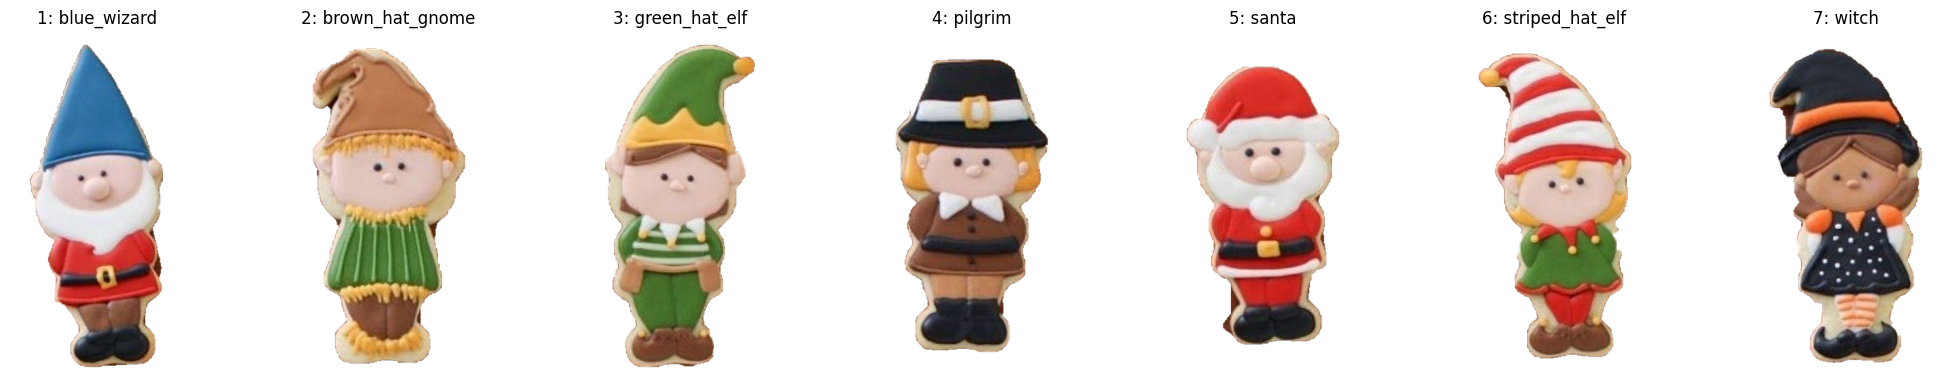

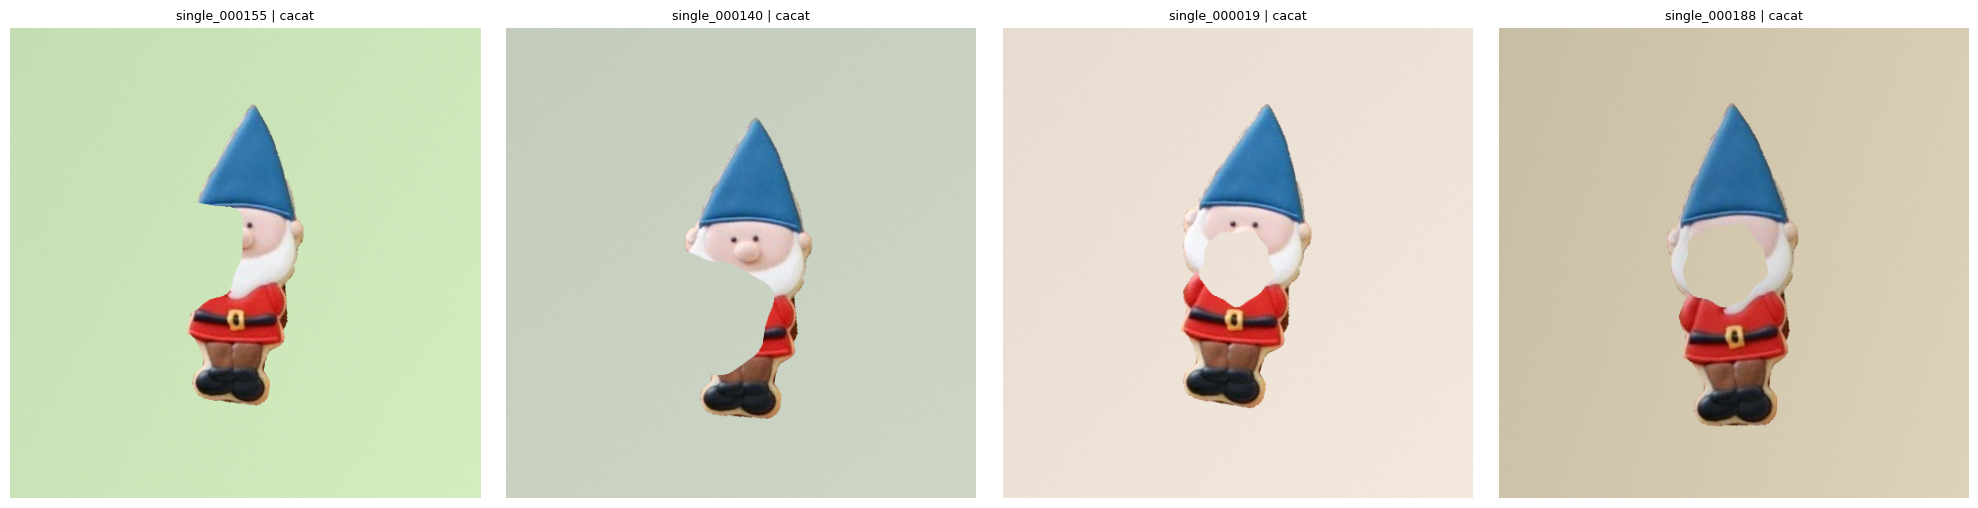

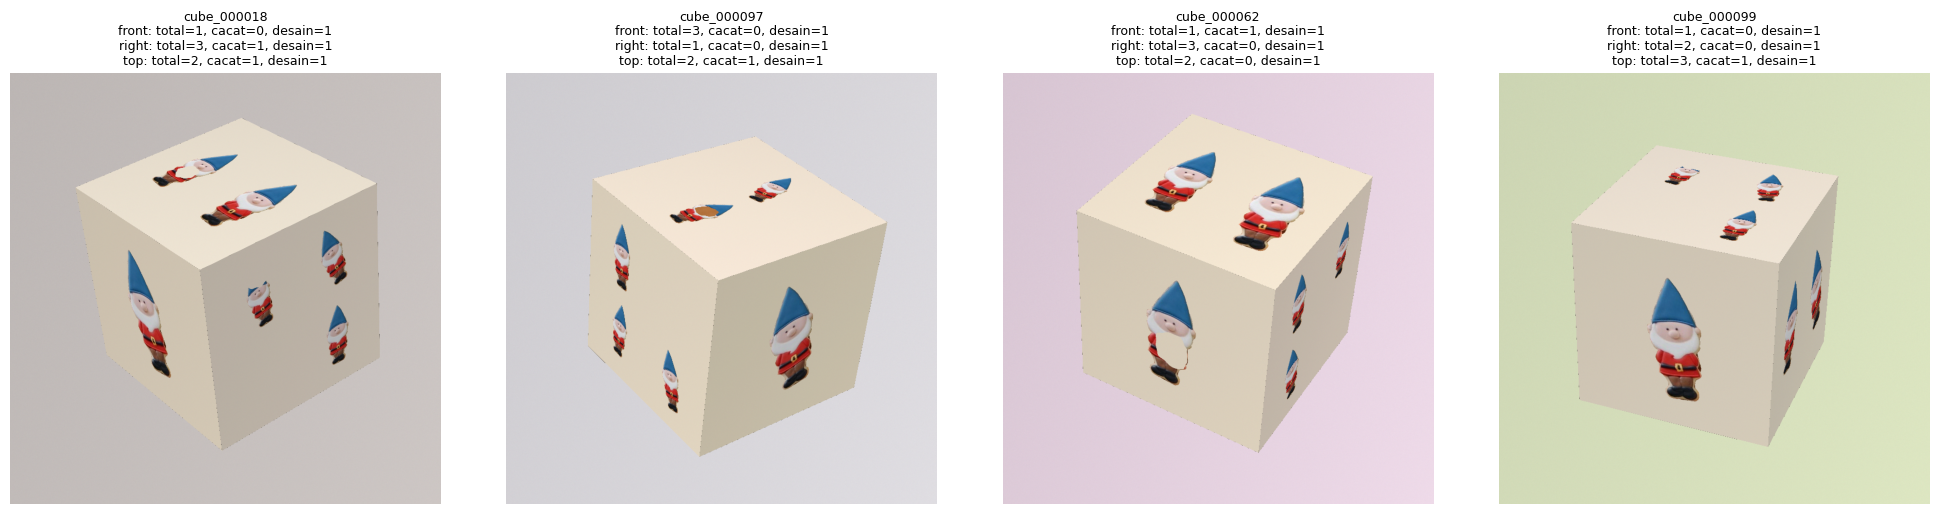

In [4]:
fig, axes = plt.subplots(1, len(references), figsize=(3*len(references),4), squeeze=False)
for ax, (design_id, ref) in zip(axes.ravel(), references.items()):
    ax.imshow(ref['rgba']); ax.set_title(f"{design_id}: {ref['name']}"); ax.axis('off')
plt.tight_layout(); plt.show()

def visualize_samples(index, labels=None, n=4, split='train'):
    subset = index[index['split'].eq(split)]
    if subset.empty:
        print(f'Tidak ada citra pada split {split}.'); return
    subset = subset.sample(min(n,len(subset)), random_state=SEED)
    fig, axes = plt.subplots(1,len(subset),figsize=(5*len(subset),5),squeeze=False)
    targets = {} if labels is None else labels.set_index('image_id').to_dict('index')
    for ax, row in zip(axes.ravel(), subset.itertuples()):
        ax.imshow(read_rgb(row.image_path)); ax.axis('off')
        title = row.image_id
        y = targets.get(row.image_id)
        if y is not None:
            if row.task == 'single':
                title += ' | cacat' if y['is_defective'] else ' | sempurna'
            else:
                title += '\n' + '\n'.join(f"{f}: total={y[f+'_total']}, cacat={y[f+'_defective']}, desain={y[f+'_design_count']}" for f in FACES)
        ax.set_title(title,fontsize=9)
    plt.tight_layout(); plt.show()

visualize_samples(single_index, single_labels)
visualize_samples(cube_index, cube_labels)

## 5. Data untuk pengembangan
Gunakan `train` untuk melatih metode dan `val` untuk memilih parameter/threshold. Gunakan `test` untuk evaluasi akhir. Jangan mengubah split berdasarkan hasil uji. Dataset satu desain belum cukup untuk menguji penghitungan desain unik.

Dataframe di bawah menyimpan path citra dan target. Muat citra sesuai kebutuhan agar penggunaan RAM terkontrol. Anotasi tambahan tersedia di folder `annotations` dan `masks`; tidak boleh digunakan sebagai masukan saat inferensi.

In [5]:
def labeled_split(index, labels, split):
    images = index[index['split'].eq(split)].copy()
    if labels is None:
        raise ValueError('Dataset ini tidak memiliki label.')
    out = images.merge(labels.drop(columns=['split','image'],errors='ignore'), on='image_id', how='left', validate='one_to_one', indicator=True)
    if not out['_merge'].eq('both').all():
        raise ValueError('Ada citra yang tidak memiliki label.')
    return out.drop(columns='_merge')

single_train = labeled_split(single_index, single_labels, 'train') if single_labels is not None else None
single_val = labeled_split(single_index, single_labels, 'val') if single_labels is not None else None
cube_train = labeled_split(cube_index, cube_labels, 'train') if cube_labels is not None else None
cube_val = labeled_split(cube_index, cube_labels, 'val') if cube_labels is not None else None
# Contoh akses: image = read_rgb(single_train.iloc[0].image_path)
# TODO: ekstraksi fitur, augmentasi train, DataLoader, pelatihan, dan pemilihan parameter.
# Terapkan transformasi geometri secara konsisten pada citra dan label spasial bila digunakan.

In [6]:
# Eksplorasi pembagian dataset Task 1
single_train = labeled_split(single_index, single_labels, 'train')
single_val = labeled_split(single_index, single_labels, 'val')
single_test = labeled_split(single_index, single_labels, 'test')

print(f"Data latih: {len(single_train)} citra (Cacat: {single_train['is_defective'].sum()}, Sempurna: {(~single_train['is_defective'].astype(bool)).sum()})")
print(f"Data validasi: {len(single_val)} citra (Cacat: {single_val['is_defective'].sum()}, Sempurna: {(~single_val['is_defective'].astype(bool)).sum()})")
print(f"Data uji (berlabel): {len(single_test)} citra (Cacat: {single_test['is_defective'].sum()}, Sempurna: {(~single_test['is_defective'].astype(bool)).sum()})")
display(single_train.head(5))


Data latih: 140 citra (Cacat: 70, Sempurna: 70)
Data validasi: 30 citra (Cacat: 15, Sempurna: 15)
Data uji (berlabel): 30 citra (Cacat: 15, Sempurna: 15)


,image_id,split,image_path,task,design_id,design_name,is_defective
0,single_000000,train,C:\Users\yosua\Documents\Archieve Kuliah\Archi...,single,1,blue_wizard,0
1,single_000002,train,C:\Users\yosua\Documents\Archieve Kuliah\Archi...,single,1,blue_wizard,0
2,single_000004,train,C:\Users\yosua\Documents\Archieve Kuliah\Archi...,single,1,blue_wizard,0
3,single_000005,train,C:\Users\yosua\Documents\Archieve Kuliah\Archi...,single,1,blue_wizard,0
4,single_000006,train,C:\Users\yosua\Documents\Archieve Kuliah\Archi...,single,1,blue_wizard,1


## 6. Implementasi mahasiswa
Isi keempat fungsi berikut. Fungsi inferensi hanya menerima **citra RGB dan referensi**; model yang telah dilatih dapat diakses dari variabel atau objek model Anda.

- Tugas 1: kembalikan `is_defective` (0/1) dan `defect_score` (0–1, semakin tinggi semakin cacat). Tetapkan threshold berdasarkan validasi.
- Tugas 2: kembalikan dict dengan enam hitungan; tambahkan tiga `*_design_count` saat leaderboard aktif. Semua hitungan berupa integer nonnegatif.
- Referensi menggunakan ID asli dan dapat bertambah dari satu menjadi tujuh desain. Jangan mengasumsikan ID berurutan atau jumlah objek yang selalu sama.

SIFT/feature matching, RANSAC, segmentasi, dan pembelajaran fitur dapat digunakan sesuai pendekatan. Notebook ini tidak menyediakan implementasi baseline.

### 6.1. Tugas 1: Metodologi Deep Learning
#### Deep Geometric Alignment & Deep Feature Difference
Pendekatan: *Menggabungkan fitur neural network dengan pencocokan dan penyelarasan geometris*
1. **Identifikasi Desain melalui Robust Inlier Matching:** Mengevaluasi korespondensi fitur geometris terhadap seluruh template referensi. Template yang cocok memiliki banyak inliers RANSAC, sedangkan karakter yang salah hanya memiliki sedikit inliers yang kebetulan cocok.
2. **Validasi Geometris Homografi:** Memastikan matriks transformasi $H$ tidak mengalami singularitas / degenerasi dengan memeriksa rasio inlier dan batas luas wajar area gingerbread (15.000 s.d. 150.000 piksel).
3. **Deep Perceptual Defect Scoring:**
   - Mengekstrak representasi fitur konvolusi spasial (ResNet mid-level features `layer2`) dari citra uji dan template yang sudah diselaraskan.
   - Menghitung peta selisih fitur mendalam di dalam area gingerbread.
   - Cacat terpotong, lubang, maupun icing hilang akan menghasilkan selisih fitur yang tajam dibandingkan kue sempurna.
   - Menghasilkan probabilitas cacat terkalibrasi (`defect_score` $\in [0.0, 1.0]$).


### 6.2. Inisialisasi Model Ekstraktor Fitur Deep Learning
Memuat arsitektur `ResNet18` dengan bobot ImageNet untuk ekstraksi fitur spasial konvolusional tingkat menengah (`layer2`).


In [7]:
# Inisialisasi arsitektur deep learning dan modul ekstraksi fitur
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Memuat arsitektur ResNet18 pada device:', device)

weights = models.ResNet18_Weights.DEFAULT
base_resnet = models.resnet18(weights=weights).to(device)
base_resnet.eval()

# Ekstraktor peta fitur spasial konvolusional (layer 2)
perceptual_feature_model = torch.nn.Sequential(*list(base_resnet.children())[:6]).to(device)
perceptual_feature_model.eval()

# Pipeline transformasi citra standar ImageNet
norm_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

print('Ekstraktor fitur Deep Learning siap.')


Memuat arsitektur ResNet18 pada device: cpu


Ekstraktor fitur Deep Learning siap.


### 6.3. Prekomputasi Deskriptor Referensi Desain
Fitur SIFT untuk ketujuh desain template gingerbread diekstraksi terlebih dahulu (hanya pada area gingerbread menggunakan alpha mask) dan disimpan ke dalam memori agar inferensi bisa running dengan cepat.


In [8]:
# Pra-komputasi fitur geometris SIFT pada seluruh template referensi
sift = cv2.SIFT_create(nfeatures=2500)
ref_sift_data = {}

for d_id, ref in references.items():
    ref_rgb = ref['rgba'][:, :, :3]
    ref_mask_u8 = (ref['mask'].astype(np.uint8)) * 255
    kp, des = sift.detectAndCompute(ref_rgb, mask=ref_mask_u8)
    ref_sift_data[d_id] = (kp, des)

print(f"Berhasil memproses {len(ref_sift_data)} referensi desain ke dalam cache:")
for d_id, ref in references.items():
    print(f"  - Desain {d_id}: {ref['name']:18s} | Fitur SIFT: {len(ref_sift_data[d_id][0])} keypoints")


Berhasil memproses 7 referensi desain ke dalam cache:
  - Desain 1: blue_wizard        | Fitur SIFT: 181 keypoints
  - Desain 2: brown_hat_gnome    | Fitur SIFT: 410 keypoints
  - Desain 3: green_hat_elf      | Fitur SIFT: 235 keypoints
  - Desain 4: pilgrim            | Fitur SIFT: 197 keypoints
  - Desain 5: santa              | Fitur SIFT: 146 keypoints
  - Desain 6: striped_hat_elf    | Fitur SIFT: 197 keypoints
  - Desain 7: witch              | Fitur SIFT: 472 keypoints


### 6.4. Modul Identifikasi Desain & Penyelarasan Geometris yang Robust
Fungsi `robust_match_and_align` mencocokkan citra masukan terhadap ke-7 desain template gingerbread:
1. Memilih desain dengan jumlah inliers RANSAC tertinggi.
2. Memverifikasi kelayakan matriks homografi (luas area silhouette gingerbread berada di rentang wajar 15.000–150.000 piksel).


In [9]:
bf_matcher = cv2.BFMatcher(cv2.NORM_L2)

def robust_match_and_align(query_rgb):
    """
    Mencari desain referensi yang tepat dan menyelaraskan template ke citra query.
    Menggunakan geometric inlier verification dan sanity check area homografi.
    """
    kp_q, des_q = sift.detectAndCompute(query_rgb, None)
    if des_q is None or len(des_q) < 8:
        return None, None, None, 0

    best_d_id = None
    max_inliers = 0
    best_H = None
    best_warped_rgb = None
    best_warped_mask = None

    h, w = query_rgb.shape[:2]

    # Evaluasi terhadap seluruh 7 desain referensi
    for d_id, ref in references.items():
        kp_ref, des_ref = ref_sift_data[d_id]
        if des_ref is None or len(des_ref) < 8:
            continue
            
        matches = bf_matcher.knnMatch(des_ref, des_q, k=2)
        good = [m for m, n in matches if m.distance < 0.75 * n.distance]
        if len(good) < 8:
            continue

        src_pts = np.float32([kp_ref[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
        dst_pts = np.float32([kp_q[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)
        H, inliers = cv2.findHomography(src_pts, dst_pts, cv2.RANSAC, 5.0)
        n_inliers = int(inliers.sum()) if inliers is not None else 0

        # Pengecekan secara geometris:
        # 1. Jumlah inliers minimal 6 dan merupakan yang terbanyak di antara semua kandidat
        # 2. Luas area siluet yang diselaraskan harus realistis (15.000 s.d. 150.000 piksel)
        if n_inliers >= 6 and n_inliers > max_inliers:
            w_mask = cv2.warpPerspective(ref['mask'].astype(np.uint8) * 255, H, (w, h)) > 128
            area = w_mask.sum()
            if 15000 <= area <= 150000:
                max_inliers = n_inliers
                best_d_id = d_id
                best_H = H
                best_warped_mask = w_mask
                best_warped_rgb = cv2.warpPerspective(ref['rgba'][:, :, :3], H, (w, h))

    return best_d_id, best_warped_rgb, best_warped_mask, max_inliers


### 6.5. Perhitungan Deep Perceptual Difference & Kalibrasi Skor Cacat (Defect)
Setelah template gingerbread yang tepat diselaraskan:
1. Area kue di-*crop* dan dinormalisasi.
2. Peta aktivasi spasial konvolusional diekstraksi dari kedua citra menggunakan `perceptual_feature_model`.
3. Peta selisih fitur dihitung di dalam area gingerbread.
4. Rata-rata selisih fitur dikalibrasi menjadi probabilitas menggunakan fungsi sigmoid terpusat pada threshold ($1.55$).


In [10]:
def compute_defect_score_robust(query_rgb):
    """
    Menghitung skor cacat menggunakan selisih fitur konvolusional ResNet terkalibrasi.
    Kembalikan: defect_score (0-1), is_defective (0/1), design_id, inliers, deep_diff
    """
    d_id, warped_rgb, warped_mask, inliers = robust_match_and_align(query_rgb)
    
    # Jika kue terpotong parah / tidak ada korespondensi yang valid -> tandai cacat
    if d_id is None or warped_rgb is None or warped_mask is None or warped_mask.sum() == 0:
        return 0.99, 1, None, 0, 2.5

    y_idx, x_idx = np.where(warped_mask)
    if len(y_idx) == 0:
        return 0.99, 1, d_id, inliers, 2.5

    ymin, ymax = y_idx.min(), y_idx.max()
    xmin, xmax = x_idx.min(), x_idx.max()
    q_crop = query_rgb[ymin:ymax+1, xmin:xmax+1]
    w_crop = warped_rgb[ymin:ymax+1, xmin:xmax+1]
    m_crop = warped_mask[ymin:ymax+1, xmin:xmax+1]

    q_t = norm_transform(Image.fromarray(q_crop)).unsqueeze(0).to(device)
    w_t = norm_transform(Image.fromarray(w_crop)).unsqueeze(0).to(device)

    with torch.no_grad():
        f_q = perceptual_feature_model(q_t)
        f_w = perceptual_feature_model(w_t)
        feat_diff = torch.norm(f_q - f_w, dim=1, keepdim=True)
        feat_diff_up = torch.nn.functional.interpolate(feat_diff, size=m_crop.shape, mode='bilinear', align_corners=False)
        feat_diff_np = feat_diff_up.squeeze().cpu().numpy()

    deep_diff_inside = float(feat_diff_np[m_crop].mean()) if m_crop.sum() > 0 else 0.0

    # Kalibrasi probabilitas skor cacat menggunakan sigmoid (thresholded pada 1.55)
    calibrated_score = float(1.0 / (1.0 + np.exp(-4.0 * (deep_diff_inside - 1.55))))
    calibrated_score = max(0.0, min(1.0, calibrated_score))
    is_def = 1 if calibrated_score >= 0.67 else 0

    return calibrated_score, is_def, d_id, inliers, deep_diff_inside


### 6.6. Visualisasi Kualitas & Peta Perbedaan Fitur (Defect Heatmap)
Visualisasi kualitatif untuk memeriksa bagaimana model deep learning mendeteksi perbedaan antara citra uji dan template yang diselaraskan.


Visualisasi Inspeksi Kue Sempurna:


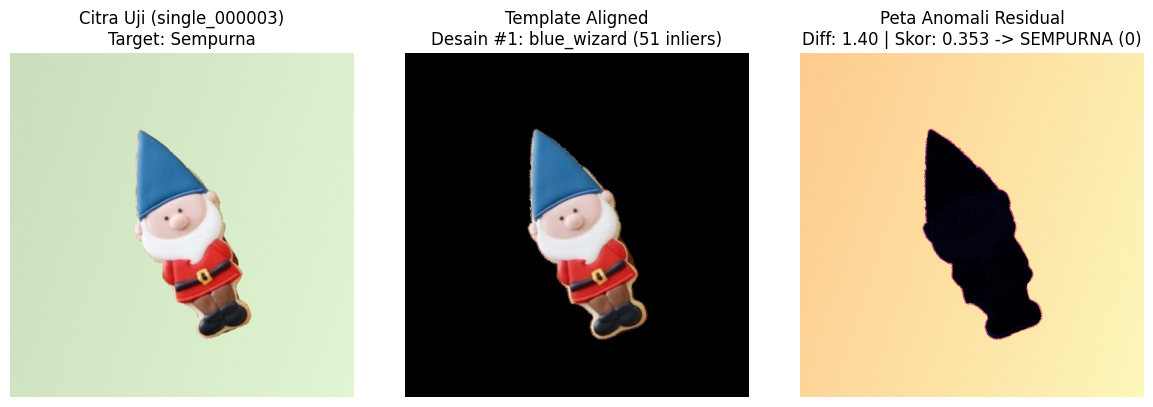

Visualisasi Inspeksi Kue Cacat:


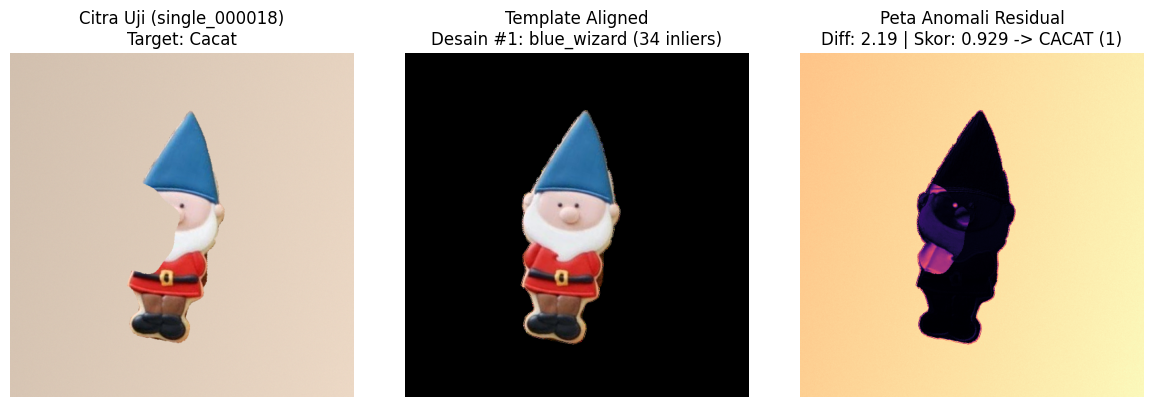

In [11]:
def inspect_gingerbread_sample(sample_row):
    """Visualisasi kualitatif: Citra Uji, Template Diselaraskan, dan Peta Perbedaan Deep Learning."""
    img_path = sample_row['image_path']
    query_rgb = read_rgb(img_path)
    score, is_def, d_id, inliers, deep_diff = compute_defect_score_robust(query_rgb)
    pred_status = "CACAT (1)" if is_def == 1 else "SEMPURNA (0)"
    
    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    axes[0].imshow(query_rgb)
    axes[0].set_title(f"Citra Uji ({sample_row['image_id']})\nTarget: {'Cacat' if sample_row['is_defective'] else 'Sempurna'}")
    axes[0].axis('off')

    if d_id is not None:
        ref = references[d_id]
        _, warped_rgb, _, _ = robust_match_and_align(query_rgb)
        axes[1].imshow(warped_rgb)
        axes[1].set_title(f"Template Aligned\nDesain #{d_id}: {ref['name']} ({inliers} inliers)")
    else:
        axes[1].text(0.5, 0.5, "Alignment Gagal", ha='center')
    axes[1].axis('off')

    diff_map = np.abs(query_rgb.astype(np.float32) - (warped_rgb.astype(np.float32) if d_id is not None else 0))
    axes[2].imshow(diff_map.mean(axis=2), cmap='magma')
    axes[2].set_title(f"Peta Anomali Residual\nDiff: {deep_diff:.2f} | Skor: {score:.3f} -> {pred_status}")
    axes[2].axis('off')
    
    plt.tight_layout()
    plt.show()

# Contoh visualisasi pada data validasi (1 kue sempurna dan 1 kue cacat)
perfect_sample = single_val[single_val['is_defective'] == 0].iloc[0]
defective_sample = single_val[single_val['is_defective'] == 1].iloc[0]
print("Visualisasi Inspeksi Kue Sempurna:")
inspect_gingerbread_sample(perfect_sample)
print("Visualisasi Inspeksi Kue Cacat:")
inspect_gingerbread_sample(defective_sample)


### 6.7. Implementasi Mahasiswa
Implementasi fungsi `predict_single_dl` 


In [12]:
def predict_single_non_dl(rgb, references):
    raise NotImplementedError('TODO: metode non-deep learning Tugas 1')

def predict_single_dl(rgb, references):
    """
    Inferensi Task 1 Deep Learning:
    - Masukan: rgb (citra masukan) dan references (dict template referensi desain)
    - Keluaran: dict dengan kunci 'is_defective' (0/1) dan 'defect_score' (float 0-1)
    """
    score, is_def, _, _, _ = compute_defect_score_robust(rgb)
    return {
        'is_defective': is_def,
        'defect_score': float(score)
    }

def predict_cube_non_dl(rgb, references):
    raise NotImplementedError('TODO: metode non-deep learning Tugas 2')

def predict_cube_dl(rgb, references):
    raise NotImplementedError('TODO: metode deep learning Tugas 2')


## 7. Validasi prediksi dan evaluasi

In [13]:
def validate_predictions(pred, expected_ids, task, leaderboard=False):
    cols = SINGLE_COLS if task == 'single' else cube_columns(leaderboard)
    if list(pred.columns) != cols:
        raise ValueError(f'Nama/urutan kolom wajib: {cols}')
    if pred.image_id.isna().any() or pred.image_id.duplicated().any():
        raise ValueError('ID kosong atau duplikat.')
    if set(pred.image_id) != set(expected_ids) or len(pred) != len(expected_ids):
        raise ValueError('ID hilang atau berlebih dibanding daftar citra.')
    values = pred[cols[1:]].to_numpy(dtype=float)
    if not np.isfinite(values).all():
        raise ValueError('Prediksi memuat NaN/inf.')
    if task == 'single':
        if not pred.is_defective.isin([0,1]).all() or not pred.defect_score.between(0,1).all():
            raise ValueError('Label harus 0/1; defect_score harus 0–1.')
    else:
        if (values < 0).any() or not np.equal(values,np.floor(values)).all():
            raise ValueError('Hitungan wajib integer nonnegatif.')
        for f in FACES:
            if (pred[f+'_defective'] > pred[f+'_total']).any():
                raise ValueError('Jumlah cacat melebihi jumlah total.')
            if leaderboard:
                d,t = pred[f+'_design_count'],pred[f+'_total']
                if ((d>t)|(d>len(references))|((t>0)&(d==0))).any():
                    raise ValueError('Jumlah desain unik tidak konsisten.')
    return pred

def aligned_targets(pred, truth, cols):
    if truth is None:
        raise ValueError('Evaluasi tidak tersedia: hidden dataset tidak memiliki label.')
    if truth.image_id.duplicated().any():
        raise ValueError('ID ground truth duplikat.')
    indexed = truth.set_index('image_id')
    missing = set(pred.image_id)-set(indexed.index)
    if missing:
        raise ValueError(f'Ground truth tidak tersedia untuk {len(missing)} citra.')
    return indexed.loc[pred.image_id,cols].to_numpy(dtype=float)

def evaluate_single(pred, truth):
    y = aligned_targets(pred, truth, ['is_defective']).ravel().astype(int)
    p = pred.is_defective.to_numpy(dtype=int)
    return {'precision':precision_score(y,p,zero_division=0),
            'recall':recall_score(y,p,zero_division=0),
            'f1':f1_score(y,p,zero_division=0),
            'balanced_accuracy':balanced_accuracy_score(y,p) if len(np.unique(y))==2 else np.nan,
            'confusion_matrix_labels_0_1':confusion_matrix(y,p,labels=[0,1]).tolist()}

def evaluate_cube(pred, truth, leaderboard=False):
    fields = ['total','defective'] + (['design_count'] if leaderboard else [])
    cols = cube_columns(leaderboard)[1:]
    y = aligned_targets(pred,truth,cols)
    p = pred[cols].to_numpy(dtype=float)
    if len(p)==0:
        raise ValueError('Tidak ada prediksi untuk dievaluasi.')
    # Kolom diurutkan field dahulu, lalu face: N × K × 3.
    errors = np.abs(p-y).reshape(len(p),len(fields),3)
    result = {}
    for k, field in enumerate(fields):
        result['mae_'+field] = float(errors[:,k,:].mean())
        for j, face in enumerate(FACES):
            result[f'mae_{face}_{field}'] = float(errors[:,k,j].mean())
    result['exact_match_face_pct'] = float((errors==0).all(axis=1).mean()*100)
    result['exact_match_image_pct'] = float((errors==0).all(axis=(1,2)).mean()*100)
    bad_truth = y.reshape(len(p),len(fields),3)[:,1,:]
    positive = bad_truth > 0
    result['mae_defective_on_defective_faces'] = float(errors[:,1,:][positive].mean()) if positive.any() else None
    return result

### 7.1. Evaluasi Kuantitatif Lengkap pada Split Validation dan Test
Menghitung Confusion Matrix, Precision, Recall, F1-score, dan Balanced Accuracy 


In [14]:
def evaluate_task1_detailed(split_df, split_name='Validation'):
    print(f"\n{'='*25} Evaluasi {split_name} ({len(split_df)} citra) {'='*25}")
    records = []
    for row in split_df.itertuples():
        res = predict_single_dl(read_rgb(row.image_path), references)
        records.append({
            'image_id': row.image_id,
            'is_defective_pred': res['is_defective'],
            'defect_score': res['defect_score'],
            'is_defective_true': int(row.is_defective)
        })
    res_df = pd.DataFrame(records)
    y_true = res_df['is_defective_true']
    y_pred = res_df['is_defective_pred']

    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    prec = precision_score(y_true, y_pred, zero_division=0)
    rec = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    bacc = balanced_accuracy_score(y_true, y_pred)
    acc = (y_true == y_pred).mean()

    print(f"Confusion Matrix:\n{cm}")
    print(f"Accuracy          : {acc * 100:.2f}%")
    print(f"Precision         : {prec:.4f}")
    print(f"Recall            : {rec:.4f}")
    print(f"F1-Score          : {f1:.4f}")
    print(f"Balanced Accuracy : {bacc:.4f}")
    return res_df

# Evaluasi pada Validation Split
val_eval = evaluate_task1_detailed(single_val, 'Validation Set')

# Evaluasi pada Test Split (berlabel)
test_eval = evaluate_task1_detailed(single_test, 'Test Set (Berlabel)')



========================= Evaluasi Validation Set (30 citra) =========================


Confusion Matrix:
[[15  0]
 [ 0 15]]
Accuracy          : 100.00%
Precision         : 1.0000
Recall            : 1.0000
F1-Score          : 1.0000
Balanced Accuracy : 1.0000

========================= Evaluasi Test Set (Berlabel) (30 citra) =========================


Confusion Matrix:
[[15  0]
 [ 0 15]]
Accuracy          : 100.00%
Precision         : 1.0000
Recall            : 1.0000
F1-Score          : 1.0000
Balanced Accuracy : 1.0000


## 8. Jalankan inferensi, evaluasi, dan simpan CSV

In [15]:
def run_inference(index, predictor, task, leaderboard=False):
    cols = SINGLE_COLS if task == 'single' else cube_columns(leaderboard)
    if index.empty:
        raise ValueError('Split yang dipilih tidak memiliki citra.')
    records = []
    for row in index.itertuples():
        result = predictor(read_rgb(row.image_path), references)
        if not isinstance(result,dict) or set(result) != set(cols[1:]):
            raise ValueError(f'Fungsi harus mengembalikan dict dengan kunci {cols[1:]}')
        records.append({'image_id':row.image_id, **result})
    pred = pd.DataFrame(records,columns=cols)
    validate_predictions(pred,index.image_id.tolist(),task,leaderboard)
    return pred

OUTPUT_DIR = WORK_DIR/'outputs'
OUTPUT_DIR.mkdir(parents=True,exist_ok=True)
SUBMISSION_DIR.mkdir(parents=True,exist_ok=True)
metrics = {}
if RUN_PREDICTIONS:
    methods = [('single_dl','single',predict_single_dl)]
    for name, task, predictor in methods:
        index = single_index if task=='single' else cube_index
        chosen = index[index['split'].eq(EVAL_SPLIT)]
        pred = run_inference(chosen,predictor,task,LEADERBOARD)
        path = SUBMISSION_DIR/f'{name}_{EVAL_SPLIT}.csv'
        pred.to_csv(path,index=False)
        print('Tersimpan:',path)
        truth = single_labels if task=='single' else cube_labels
        if truth is not None and set(pred.image_id).issubset(set(truth.image_id)):
            metrics[name] = evaluate_single(pred,truth) if task=='single' else evaluate_cube(pred,truth,LEADERBOARD)
    display(pd.DataFrame(metrics).T)
else:
    print('Isi empat fungsi mahasiswa, kemudian ubah RUN_PREDICTIONS=True dan jalankan ulang sel ini.')

Tersimpan: C:\Users\yosua\Documents\Archieve Kuliah\Archieve Semester 5\COMVIS\Mini_Project\submissions\submission_tugas1_dl\single_dl_test.csv


,precision,recall,f1,balanced_accuracy,confusion_matrix_labels_0_1
single_dl,1.0,1.0,1.0,1.0,"[[15, 0], [0, 15]]"


## 9. Template CSV dan unduhan
Template berikut berisi **kolom prediksi kosong**, bukan jawaban dan bukan submission valid. Isi melalui metode Anda sebelum dikumpulkan. Gunakan ID dan urutan dari sample submission resmi.

In [16]:
for task,index in [('single',single_index),('cube',cube_index)]:
    chosen = index[index['split'].eq(EVAL_SPLIT)]
    cols = SINGLE_COLS if task=='single' else cube_columns(LEADERBOARD)
    template = pd.DataFrame({'image_id':chosen.image_id.tolist()}).reindex(columns=cols)
    template.to_csv(OUTPUT_DIR/f'template_{task}_{EVAL_SPLIT}.csv',index=False)
print('Folder keluaran:',OUTPUT_DIR)
# Unduh satu berkas setelah dihasilkan:
# from google.colab import files
# files.download(str(OUTPUT_DIR / f'cube_non_dl_{EVAL_SPLIT}.csv'))

Folder keluaran: C:\Users\yosua\Documents\Archieve Kuliah\Archieve Semester 5\COMVIS\Mini_Project\scratch\task1_dl\outputs


### 9.1. Inferensi Hidden Test & Buat CSV output
1. `single_dl_hidden_full.csv` (3 kolom standar: `image_id, is_defective, defect_score`)
2. `single_dl_hidden_kaggle.csv` (2 kolom sesuai format Kaggle: `image_id, is_defective`)


In [17]:
def prepare_hidden_root():
    if HIDDEN_DIR:
        candidate = Path(HIDDEN_DIR)
    elif (REPO_ROOT / 'hidden_students' / 'single' / 'hidden' / 'images').is_dir():
        candidate = REPO_ROOT / 'hidden_students'
    else:
        WORK_DIR.mkdir(parents=True, exist_ok=True)
        if HIDDEN_ZIP_PATH is not None and HIDDEN_ZIP_PATH.exists():
            archive = HIDDEN_ZIP_PATH
        else:
            import gdown
            archive = WORK_DIR / 'hidden_students.zip'
            if not archive.exists() or not zipfile.is_zipfile(archive):
                gdown.download(url=HIDDEN_URL, output=str(archive), fuzzy=True, quiet=False)
        if not zipfile.is_zipfile(archive):
            raise ValueError(f'hidden_students.zip bukan ZIP valid: {archive}')
        digest = _sha256_file(archive, 12)
        folder = WORK_DIR / f'hidden_{digest}'
        if not (folder / '.complete').exists():
            _safe_extract_zip(archive, folder)
            (folder / '.complete').touch()
        candidate = folder
    roots = sorted({p.parents[2].resolve() for p in candidate.rglob('images') if p.parent.name == 'hidden' and p.parent.parent.name == 'single'})
    if len(roots) != 1:
        raise ValueError(f'Harus ada satu folder single/hidden/images, ditemukan: {roots}')
    return roots[0]

HIDDEN_ROOT = prepare_hidden_root()
HIDDEN_IMAGE_DIR = HIDDEN_ROOT / "single" / "hidden" / "images"
kag_hits = sorted(HIDDEN_ROOT.rglob("sample_submission_task1_kaggle.csv"))
KAGGLE_TEMPLATE = kag_hits[0] if kag_hits else (HIDDEN_ROOT / "sample_submission_task1_kaggle.csv")

if not HIDDEN_IMAGE_DIR.is_dir():
    raise FileNotFoundError(f"Folder citra hidden tidak ditemukan: {HIDDEN_IMAGE_DIR}")
if not KAGGLE_TEMPLATE.is_file():
    raise FileNotFoundError(f"Template sample submission tidak ditemukan: {KAGGLE_TEMPLATE}")

submission_template = pd.read_csv(KAGGLE_TEMPLATE, dtype={"image_id": str})

hidden_index = pd.DataFrame({
    "image_id": submission_template["image_id"],
    "split": "hidden",
    "image_path": [
        str(HIDDEN_IMAGE_DIR / f"{image_id}.png")
        for image_id in submission_template["image_id"]
    ],
    "task": "single"
})

missing_images = hidden_index.loc[~hidden_index["image_path"].map(lambda p: Path(p).exists())]
if not missing_images.empty:
    raise FileNotFoundError(f"Terdapat citra hidden yang hilang: {len(missing_images)}")

print(f"Memulai inferensi Deep Learning pada {len(hidden_index)} citra hidden test...")

hidden_predictions = run_inference(
    hidden_index,
    predict_single_dl,
    task="single",
    leaderboard=False
)

# 1. Simpan output full 3 kolom di subfolder submission_tugas1_dl/
SUBMISSION_DIR.mkdir(parents=True, exist_ok=True)
full_output_path = SUBMISSION_DIR / "single_dl_hidden_full.csv"
hidden_predictions.to_csv(full_output_path, index=False)

# 2. Format 2 kolom untuk Kaggle
kaggle_predictions = hidden_predictions[["image_id", "is_defective"]]

# Validasi format sebelum submit
if not kaggle_predictions["image_id"].equals(submission_template["image_id"]):
    raise ValueError("Urutan ID citra tidak cocok dengan template Kaggle!")
if not kaggle_predictions["is_defective"].isin([0, 1]).all():
    raise ValueError("Prediksi harus bernilai 0 atau 1!")

kaggle_output_path = SUBMISSION_DIR / "single_dl_hidden_kaggle.csv"
kaggle_submission_path = SUBMISSION_DIR / "kaggle_task1_dl_submission.csv"
kaggle_predictions.to_csv(kaggle_output_path, index=False)
kaggle_predictions.to_csv(kaggle_submission_path, index=False)

print("="*60)
print("HASIL BERHASIL DISIMPAN KE SUBFOLDER TUGAS 1 DL:")
print(f"1. Full (3 kolom)   : {full_output_path}")
print(f"2. Kaggle (2 kolom) : {kaggle_output_path}")
print(f"3. Kaggle copy      : {kaggle_submission_path}")
print("="*60)
print("Distribusi Prediksi Kualitas pada Hidden Dataset:")
print(kaggle_predictions["is_defective"].value_counts().rename({0: "Sempurna (0)", 1: "Cacat (1)"}))
display(kaggle_predictions.head(10))

Memulai inferensi Deep Learning pada 700 citra hidden test...


HASIL BERHASIL DISIMPAN KE SUBFOLDER TUGAS 1 DL:
1. Full (3 kolom)   : C:\Users\yosua\Documents\Archieve Kuliah\Archieve Semester 5\COMVIS\Mini_Project\submissions\submission_tugas1_dl\single_dl_hidden_full.csv
2. Kaggle (2 kolom) : C:\Users\yosua\Documents\Archieve Kuliah\Archieve Semester 5\COMVIS\Mini_Project\submissions\submission_tugas1_dl\single_dl_hidden_kaggle.csv
3. Kaggle copy      : C:\Users\yosua\Documents\Archieve Kuliah\Archieve Semester 5\COMVIS\Mini_Project\submissions\submission_tugas1_dl\kaggle_task1_dl_submission.csv
Distribusi Prediksi Kualitas pada Hidden Dataset:
is_defective
Sempurna (0)    369
Cacat (1)       331
Name: count, dtype: int64


,image_id,is_defective
0,single_01712c1fd2f6dd06,1
1,single_01d905cc09397a06,1
2,single_01f32fe34de94ecd,0
3,single_01f84dc46a4f545f,0
4,single_0250b1b8378a0018,0
5,single_0254cff51811d84a,1
6,single_028fb7cf6f7157ee,1
7,single_02f4b25b00c319c0,0
8,single_03607e96b5f510be,0
9,single_0377180dc3595d74,0
